Cum influenteaza tehnicile de design inselator si de falsificare a interfetei AI (Dark Patterns si UI Spoofing) nivelul de anxietate AI, rata de erori si abandonul utilizatorului comparativ cu un design etic si transparent.

In [31]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

#date reale colectate din Google Forms
df = pd.read_csv('../data/real_experiment_data.csv')

#Standardizare nume coloane
df.columns = [
    'timestamp', 'scenario', 'task_completion_time_sec', 'error_made',
    'decision_abandon', 'spoof_alert_present', 'tech_experience',
    'baseline_ai_trust', 'perceived_intrusiveness', 'perceived_transparency',
    'perceived_authenticity', 'ai_anxiety_score'
]

#eliminare randuri incomplete
print(f"Dimensiune initiala set date: {df.shape[0]} rânduri, {df.shape[1]} coloane")
print("\nValori lipsa per coloana:\n", df.isnull().sum())

df = df.dropna().reset_index(drop=True)
print(f"\nDimensiune dupa curatare: {df.shape[0]} randuri valide")

print("\n--- Mediile indicatorilor per Scenariu (A vs B vs C) ---")
print(df.groupby('scenario')[['ai_anxiety_score', 'error_made', 'decision_abandon', 'task_completion_time_sec']].mean().round(2))

Dimensiune initiala set date: 83 rânduri, 12 coloane

Valori lipsa per coloana:
 timestamp                   0
scenario                    0
task_completion_time_sec    0
error_made                  0
decision_abandon            0
spoof_alert_present         0
tech_experience             1
baseline_ai_trust           1
perceived_intrusiveness     1
perceived_transparency      1
perceived_authenticity      1
ai_anxiety_score            1
dtype: int64

Dimensiune dupa curatare: 82 randuri valide

--- Mediile indicatorilor per Scenariu (A vs B vs C) ---
          ai_anxiety_score  error_made  decision_abandon  \
scenario                                                   
A                     1.78        0.00              0.04   
B                     2.60        0.88              0.08   
C                     2.73        0.77              0.23   

          task_completion_time_sec  
scenario                            
A                            16.30  
B                            14

Ce intelegem din tabel:
- ai_anxiety_score creste semnificativ de la interfaata transparenta la interfata Dark Patterns, dar cel mai mult la scenariul C de UI Spoofing (2.73). Aceasta crestere nu vine de la lipsa de experienta ci din intruzivitate si scaderea autenticitatii.
- error_made are cel mai puternic efect, userul nu este pacalit in primul stenariu, dar rata creste pe rand in B si in C. La B marea majoritate a cazut in capcana interfetei lasand bifata optiunea de partajare a datelor sau autorizand alerta falsa de securitate AI.
- decision_abandon: aici se vede diferenta cristica dintre Dark Patterns si UI Spoofing. In B utilizatorii sunt pacaliti fara sa renunte, in timp ce in C alerta falsa de securitate distruge increderea in autenticitatea paginii si face ca rata de abandon sa sara la 23%.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# preprocesare si encoding
df_encoded = pd.get_dummies(df, columns=['scenario'], drop_first=True)
X = df_encoded.drop(columns=['timestamp', 'decision_abandon'])
y = df_encoded['decision_abandon']

# impartirea datelor
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# antrenare Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# predictie
y_pred = rf_model.predict(X_test)

# raport de clasifiecare
report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()
report_df.index = ['0 (Pastreaza)', '1 (Abandoneaza)', 'accuracy', 'macro avg', 'weighted avg']

print(f"Acuratete generala: {accuracy_score(y_test, y_pred):.2f}\n")
display(report_df.round(2))

Acuratete generala: 0.94



,precision,recall,f1-score,support
0 (Pastreaza),0.94,1.00,0.97,15.00
1 (Abandoneaza),1.00,0.50,0.67,2.00
accuracy,0.94,0.94,0.94,0.94
macro avg,0.97,0.75,0.82,17.00
weighted avg,0.94,0.94,0.93,17.00


17 date de test (20%)
support: 15 participanti au finalizat, 2 au abandonat.
Precision: clasa 1 (100%) pentru ca l-a gasit fix pe acela care a abandonat. cati a nimerit dintre cei prezis ca 1/total cati a prezis ca 1.
clasa 0 (94%) pentru ca din 16 participanti clasificati ca finalizand sarcina, 15 au finalizat.
Recall: clasa 1 (50%) dintre cei 2 participanti care au abandonat pe unul l-a ratat.
clasa 0 (100%) i-a identificat pe toti care au finalizat sarcina.
F1-score: ofera evaluare echilibrata, penalizeaza rata mai scazuta de detectie pe clasa minoritara.
Accuracy: modelul a clasificat corect 16 din 17 participanti.
Macro avg: media neponderata.
weighted avg: media ponderata in functie de fiecare clasa.
    

C:\Users\Administrator\AppData\Local\Temp\ipykernel_20176\626193365.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


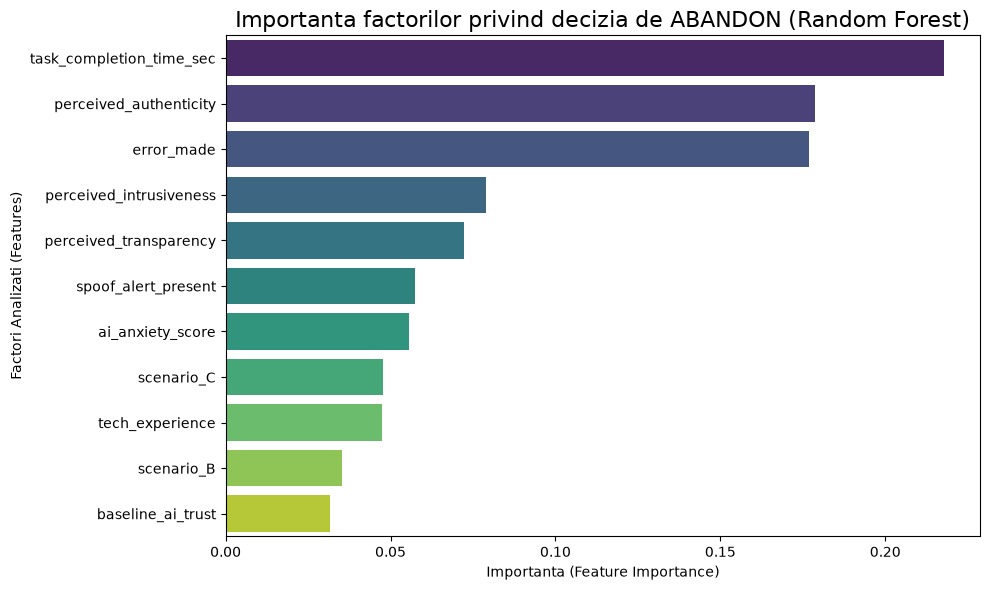

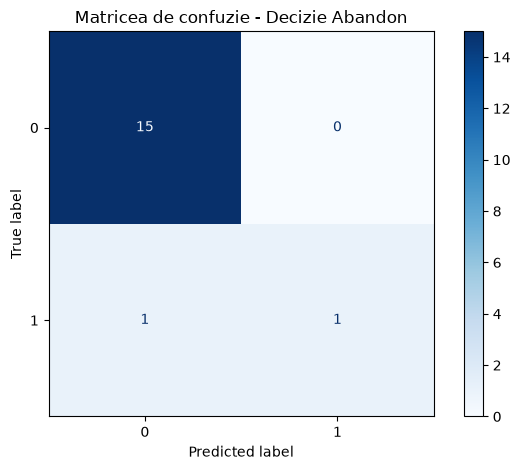

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')

plt.title('Importanta factorilor privind decizia de ABANDON (Random Forest)', fontsize=16)
plt.xlabel('Importanta (Feature Importance)', fontsize=10)
plt.ylabel('Factori Analizati (Features)', fontsize=10)
plt.tight_layout()

plt.show()

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues')
plt.title('Matricea de confuzie - Decizie Abandon')
plt.tight_layout()
plt.show()

Acuratete pe setul de test (Anxietate AI): 0.76
Acuratete medie 5-Fold Cross-Validation: 0.82



,precision,recall,f1-score,support
0 (Anxietate scazuta <=3),0.82,0.82,0.82,11.00
1 (Anxietate ridicata >=4),0.67,0.67,0.67,6.00
accuracy,0.76,0.76,0.76,0.76
macro avg,0.74,0.74,0.74,17.00
weighted avg,0.76,0.76,0.76,17.00


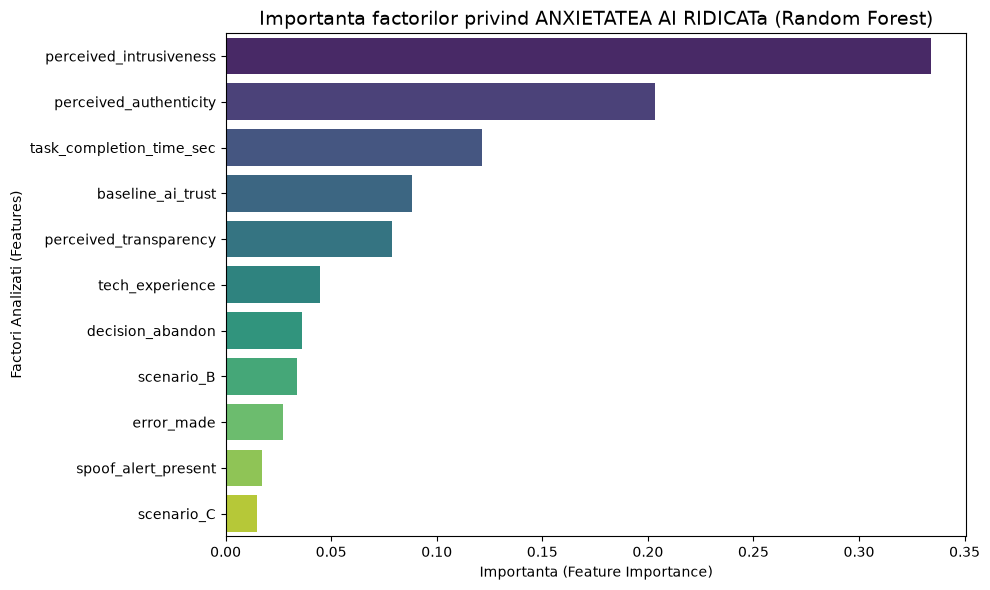

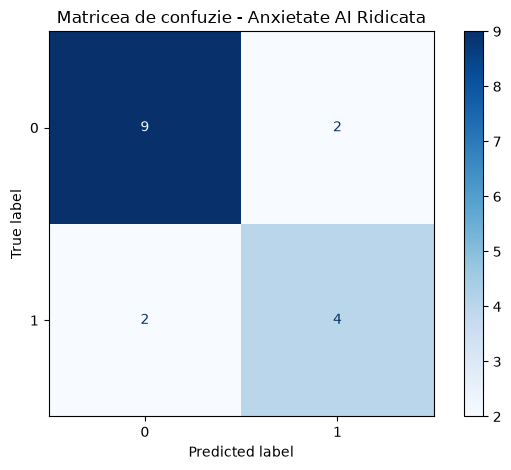

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

#anxietate ridicata (scor >= 4 pe scara 1-5)
df_anx = pd.get_dummies(df, columns=['scenario'], drop_first=True)
df_anx['high_ai_anxiety'] = (df_anx['ai_anxiety_score'] >= 4).astype(int)

X_anx = df_anx.drop(columns=['timestamp', 'ai_anxiety_score', 'high_ai_anxiety'])
y_anx = df_anx['high_ai_anxiety']

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_anx, y_anx, test_size=0.2, random_state=42, stratify=y_anx)

rf_anx = RandomForestClassifier(n_estimators=100, random_state=42)
rf_anx.fit(X_train_a, y_train_a)
y_pred_a = rf_anx.predict(X_test_a)

cv_scores = cross_val_score(rf_anx, X_anx, y_anx, cv=5, scoring='accuracy')

print(f"Acuratete pe setul de test (Anxietate AI): {accuracy_score(y_test_a, y_pred_a):.2f}")
print(f"Acuratete medie 5-Fold Cross-Validation: {cv_scores.mean():.2f}\n")

# 4. Raport de clasificare
report_anx = pd.DataFrame(classification_report(y_test_a, y_pred_a, output_dict=True, zero_division=0)).transpose()
report_anx.index = ['0 (Anxietate scazuta <=3)', '1 (Anxietate ridicata >=4)', 'accuracy', 'macro avg', 'weighted avg']
display(report_anx.round(2))

#feature importance pentru modelul de anxietate
importances_anx = pd.Series(rf_anx.feature_importances_, index=X_anx.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances_anx.values, y=importances_anx.index, hue=importances_anx.index, palette='viridis', legend=False)
plt.title('Importanta factorilor privind ANXIETATEA AI RIDICATa (Random Forest)', fontsize=14)
plt.xlabel('Importanta (Feature Importance)', fontsize=10)
plt.ylabel('Factori Analizati (Features)', fontsize=10)
plt.tight_layout()
plt.show()

#matricea de confuzie pentru modelul de anxietate
ConfusionMatrixDisplay.from_estimator(rf_anx, X_test_a, y_test_a, cmap='Blues')
plt.title('Matricea de confuzie - Anxietate AI Ridicata')
plt.tight_layout()
plt.show()

precision: clasa 0, 9 corecte si 2 care aveau de fapt anxietate ridicata.
            clasa 1, 4 corecte si 2 care aveay de fapt anxietate scazuta
recall: clasa 0, a nimerit 9 din 11 persoane cu anxietate scazuta, iar pe 2 i-a clasificat gresit ca avand axietate ridicata.
        clasa 1, din 6 participanti din setul de test care chiar au raportat anxietate ridicata, modelul a identificat corect 4.